# Crop Yield Prediction via Multimodal Data Fusion: walkthrough

This notebook walks through the full pipeline step by step, using the project's own package (`cropyield/`):

1. Load the fused district × crop × season dataset
2. Explore the three modalities: satellite NDVI, weather, soil
3. Feature engineering
4. Leave-one-year-out (LOYO) validation
5. Model comparison and early vs late fusion
6. Modality ablation: does fusion help?
7. Explainability with SHAP
8. Forecasting a scenario with the deployed model

Run `python -m cropyield.train` first (the setup script does this) so the trained model and reports exist.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cropyield.config import DATASET_PATH, NDVI_SERIES_PATH, REPORT_DIR, MODALITIES, ALL_FEATURES, TARGET
from cropyield.features import build_features, modality_columns

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREEN, OCHRE, BLUE, BROWN = "#2f7d4f", "#c48a1c", "#3b78b5", "#9a6a3a"
pd.set_option("display.precision", 3)

## 1. The fused dataset
One row = one district, one crop, one season. Wheat seasons are labelled by harvest year.

In [2]:
raw = pd.read_csv(DATASET_PATH)
print(f"{len(raw)} rows | {raw.district.nunique()} districts | {raw.state.nunique()} states | "
      f"{raw.year.min()}-{raw.year.max()} | weather source: {raw.weather_source.iloc[0]}")
raw.head()

440 rows | 32 districts | 11 states | 2014-2024 | weather source: synthetic


,district,state,crop,year,lat,lon,weather_source,ndvi_early,ndvi_mid,ndvi_peak,...,rh_mean_pct,gdd,heat_stress_days,soil_ph,soil_n_kg_ha,soil_oc_pct,sand_pct,silt_pct,clay_pct,yield_tonnes_ha
0,Ludhiana,Punjab,Wheat,2014,30.90,75.85,synthetic,0.218,0.693,0.790,...,46.026,2055.203,2.0,7.350,209.611,0.485,49.501,29.847,20.652,4.427
1,Ludhiana,Punjab,Rice,2014,30.90,75.85,synthetic,0.225,0.641,0.595,...,71.646,2258.700,1.0,7.403,189.470,0.514,52.938,24.431,22.631,3.882
2,Patiala,Punjab,Wheat,2014,30.34,76.39,synthetic,0.235,0.741,0.806,...,45.709,2114.397,1.0,7.830,262.217,0.615,52.200,25.987,21.813,4.861
3,Patiala,Punjab,Rice,2014,30.34,76.39,synthetic,0.287,0.745,0.727,...,73.272,2086.391,0.0,8.078,224.106,0.506,52.741,26.237,21.022,3.661
4,Amritsar,Punjab,Wheat,2014,31.63,74.87,synthetic,0.199,0.705,0.689,...,46.301,1896.121,0.0,8.033,198.729,0.580,50.599,30.891,18.510,4.492


In [3]:
raw.groupby("crop")[TARGET].describe()

,count,mean,std,min,25%,50%,75%,max
crop,,,,,,,,
Rice,220.0,3.186,0.761,1.822,2.593,3.153,3.790,4.973
Wheat,220.0,3.039,0.987,0.848,2.411,2.811,3.762,5.571


## 2. Exploring the modalities
### Yield by state and crop

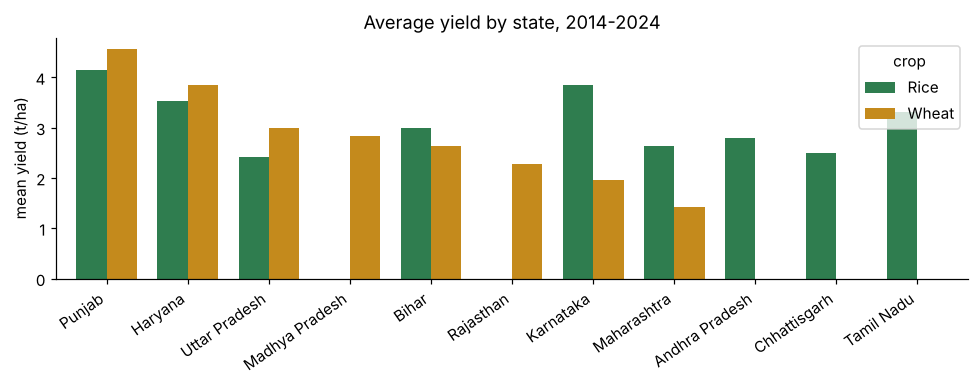

In [4]:
by_state = raw.groupby(["state", "crop"])[TARGET].mean().unstack()
ax = by_state.sort_values("Wheat", ascending=False).plot.bar(color=[GREEN, OCHRE], figsize=(9, 3.6), width=0.75)
ax.set_ylabel("mean yield (t/ha)"); ax.set_xlabel(""); ax.set_title("Average yield by state, 2014-2024")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()

### Satellite: the NDVI season curve
Each season the canopy greens up, peaks around flowering, and browns at maturity. In 2022 the March heatwave makes wheat senesce early.

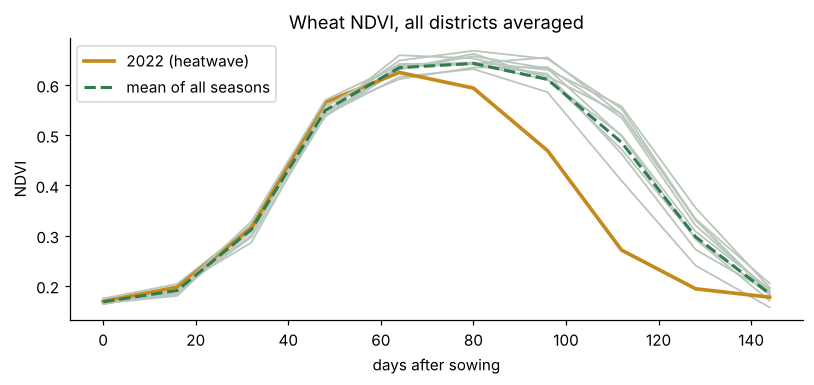

In [5]:
ndvi = pd.read_csv(NDVI_SERIES_PATH)
wheat = ndvi[ndvi.crop == "Wheat"].groupby(["year", "days_after_sowing"]).ndvi.mean().unstack(0)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for year in wheat.columns:
    ax.plot(wheat.index, wheat[year], color=OCHRE if year == 2022 else "#b9c7bc", lw=2.4 if year == 2022 else 1.2,
            label="2022 (heatwave)" if year == 2022 else None)
ax.plot(wheat.index, wheat.mean(axis=1), color=GREEN, lw=2, ls="--", label="mean of all seasons")
ax.set_xlabel("days after sowing"); ax.set_ylabel("NDVI"); ax.set_title("Wheat NDVI, all districts averaged"); ax.legend()
plt.tight_layout()

### How each modality relates to yield

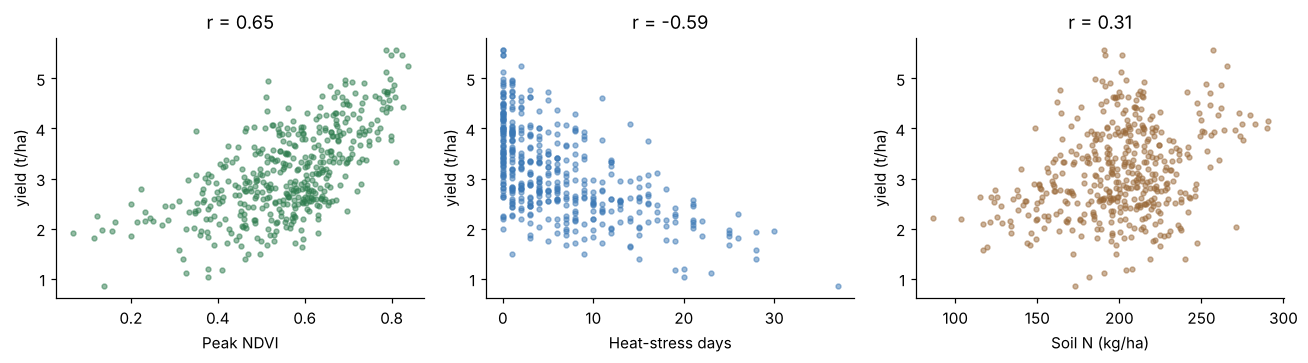

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
pairs = [("ndvi_peak", "Peak NDVI", GREEN), ("heat_stress_days", "Heat-stress days", BLUE), ("soil_n_kg_ha", "Soil N (kg/ha)", BROWN)]
for ax, (col, label, color) in zip(axes, pairs):
    ax.scatter(raw[col], raw[TARGET], s=10, alpha=0.5, color=color)
    ax.set_xlabel(label); ax.set_ylabel("yield (t/ha)")
    ax.set_title(f"r = {raw[col].corr(raw[TARGET]):.2f}")
plt.tight_layout()

No single variable explains yield on its own; the relationships are noisy and partly non-linear (heat damage only appears after a threshold). That is the motivation for fusing modalities and using non-linear models.

## 3. Feature engineering
`build_features` adds NDVI phenology metrics (green-up slope, senescence, seasonal integral), the diurnal temperature range, a cross-modal rainfall × soil-N interaction and a crop flag.

In [7]:
df = build_features(raw)
for name, cols in MODALITIES.items():
    print(f"{name:<10} ({len(cols):2d}): {', '.join(cols)}")
print(f"\nTotal model features: {len(ALL_FEATURES)}")
df[["ndvi_growth_slope", "ndvi_senescence", "ndvi_auc", "temp_range_c", "rainfall_x_soil_n"]].describe().T

Satellite  ( 7): ndvi_early, ndvi_mid, ndvi_peak, ndvi_late, ndvi_growth_slope, ndvi_senescence, ndvi_auc
Weather    (11): rainfall_mm, rainfall_cv, flowering_rainfall_mm, dry_spell_days, tmax_mean_c, tmin_mean_c, solar_radiation_mj, rh_mean_pct, gdd, heat_stress_days, temp_range_c
Soil       ( 6): soil_ph, soil_n_kg_ha, soil_oc_pct, sand_pct, silt_pct, clay_pct

Total model features: 26


,count,mean,std,min,25%,50%,75%,max
ndvi_growth_slope,440.0,0.165,0.071,-0.100,0.125,0.174,0.211,0.320
ndvi_senescence,440.0,29.153,10.297,-9.640,23.070,29.225,34.895,61.340
ndvi_auc,440.0,1.400,0.232,0.711,1.251,1.390,1.544,1.948
temp_range_c,440.0,10.190,2.490,7.432,7.696,10.262,12.679,12.859
rainfall_x_soil_n,440.0,78344.477,80138.164,2612.716,12296.360,52833.414,115865.732,366801.152


## 4. Leave-one-year-out validation
For each season, train on the other ten and predict the held-out one. A random split would put districts from the same
season (sharing the same monsoon and heat) in both train and test, which inflates the score. Below: LOYO vs a random
5-fold split for the same model.

In [8]:
from sklearn.model_selection import KFold, cross_val_predict
from cropyield.models import make_models
from cropyield.validation import loyo, metrics

model = make_models()["LightGBM"]
loyo_preds, _ = loyo(df, ALL_FEATURES, model)
random_preds = cross_val_predict(model, df[ALL_FEATURES], df[TARGET], cv=KFold(5, shuffle=True, random_state=0))
pd.DataFrame({"Leave-one-year-out": metrics(loyo_preds.actual, loyo_preds.predicted),
              "Random 5-fold (optimistic)": metrics(df[TARGET], random_preds)}).T

,RMSE,MAE,R2,MAPE_pct
Leave-one-year-out,0.372,0.290,0.822,9.694
Random 5-fold (optimistic),0.369,0.287,0.825,9.564


The random split scores slightly better because test rows share a season with training rows, so the model has already seen that year's monsoon and heat. The gap is small here because the simulated season-wide shocks are moderate; with real data, where one drought hits every district at once, random splits can be far more optimistic. LOYO matches how the model would really be used, so every reported score uses it.

## 5. Model comparison: early vs late fusion
Computed by `python -m cropyield.train` (all six models × 11 folds).

In [9]:
comparison = pd.read_csv(REPORT_DIR / "model_comparison.csv")
comparison

,Model,Fusion,RMSE,MAE,R2,MAPE_pct,CV_seconds
0,LightGBM,Early,0.372,0.290,0.822,9.694,1.9
1,XGBoost,Early,0.374,0.291,0.820,9.697,3.1
2,Random Forest,Early,0.378,0.291,0.817,9.892,4.7
3,Ridge Regression,Early,0.388,0.303,0.807,10.524,0.1
4,Late Fusion (stacked),Late,0.412,0.326,0.781,11.087,26.2
5,Neural Net (MLP),Early,0.420,0.332,0.774,11.410,2.4


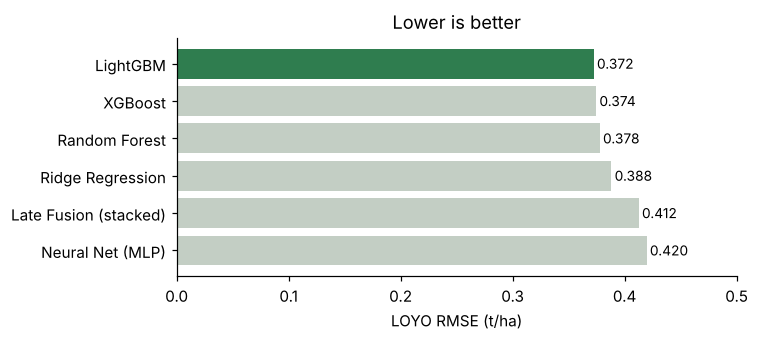

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
c = comparison.sort_values("RMSE", ascending=False)
ax.barh(c.Model, c.RMSE, color=[GREEN if i == len(c) - 1 else "#c3cec4" for i in range(len(c))])
for y, v in enumerate(c.RMSE):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("LOYO RMSE (t/ha)"); ax.set_xlim(0, 0.5); ax.set_title("Lower is better"); plt.tight_layout()

* **Boosted trees beat Ridge regression**: heat thresholds and saturating nitrogen response are non-linear.
* **Early fusion beats late fusion**: one joint model can learn cross-modal interactions (e.g. heat matters more when the canopy is weak).
* **The MLP trails**: 440 rows is too little data for a neural network.

## 6. Modality ablation: does fusion help?

,Modalities,RMSE,R2,MAPE_pct
2,Soil,0.590,0.553,16.562
1,Weather,0.528,0.642,14.216
0,Satellite,0.484,0.700,13.143
3,Satellite + Weather,0.426,0.767,11.570
5,Weather + Soil,0.409,0.785,10.632
4,Satellite + Soil,0.403,0.792,10.659
6,All three (early fusion),0.372,0.822,9.694


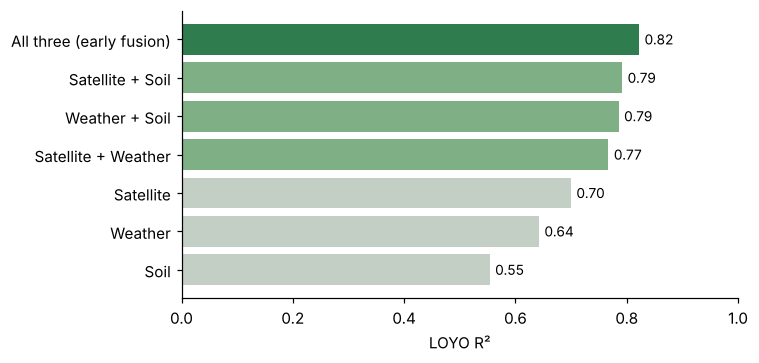

In [11]:
ablation = pd.read_csv(REPORT_DIR / "modality_ablation.csv").sort_values("R2")
fig, ax = plt.subplots(figsize=(7, 3.4))
colors = {1: "#c3cec4", 2: "#7faf85", 3: GREEN}
ax.barh(ablation.Modalities, ablation.R2, color=[colors[n] for n in ablation.n_modalities])
for y, v in enumerate(ablation.R2):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("LOYO R²"); plt.tight_layout()
ablation[["Modalities", "RMSE", "R2", "MAPE_pct"]]

## 7. Explainability with SHAP
For gradient-boosted trees we use the exact TreeSHAP values built into LightGBM. Every prediction = base value + sum of feature contributions.

Deployed model: LightGBM | max additivity error: 1.20e-14


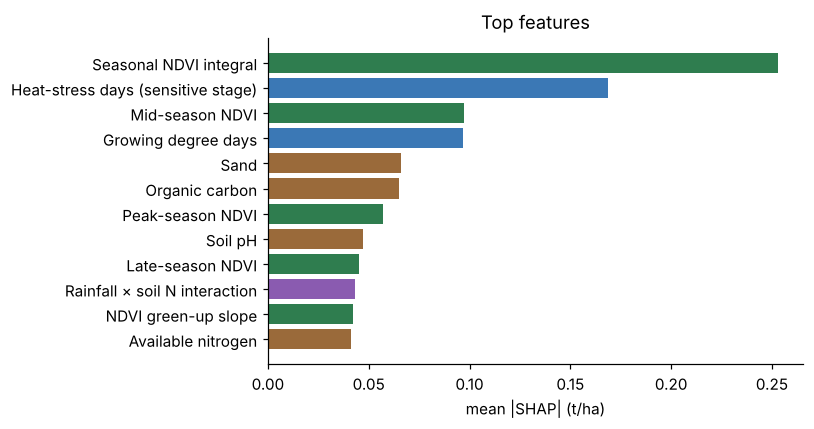

In [12]:
import joblib
from cropyield.config import MODEL_BUNDLE_PATH, FEATURE_INFO, modality_of
from cropyield.explain import contributions

bundle = joblib.load(MODEL_BUNDLE_PATH)
contrib, base = contributions(bundle["model"], df[ALL_FEATURES])
check = np.abs(base + contrib.sum(axis=1) - bundle["model"].predict(df[ALL_FEATURES])).max()
print(f"Deployed model: {bundle['model_name']} | max additivity error: {check:.2e}")

importance = contrib.abs().mean().sort_values(ascending=False)
palette = {"Satellite": GREEN, "Weather": BLUE, "Soil": BROWN, "Cross-modal": "#8a5bb0", "Context": "#999"}
top = importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh([FEATURE_INFO[f]["label"] for f in top.index], top.values, color=[palette[modality_of(f)] for f in top.index])
ax.set_xlabel("mean |SHAP| (t/ha)"); ax.set_title("Top features"); plt.tight_layout()

In [13]:
share = importance.groupby(importance.index.map(modality_of)).sum()
(100 * share / share.sum()).sort_values(ascending=False).round(1).rename("share of explanation (%)")

Satellite      42.8
Weather        34.1
Soil           19.7
Cross-modal     3.4
Context         0.0
Name: share of explanation (%), dtype: float64

## 8. Forecasting a scenario
Karnal wheat: a typical season vs a heatwave during grain filling.

In [14]:
from cropyield.predict import YieldPredictor

predictor = YieldPredictor()
typical = predictor.default_inputs("Wheat", "Karnal")
heatwave = {**typical, "heat_stress_days": typical["heat_stress_days"] + 15,
            "tmax_mean_c": typical["tmax_mean_c"] + 2, "ndvi_late": typical["ndvi_late"] * 0.75}

for name, inputs in [("Typical season", typical), ("Heatwave", heatwave)]:
    r = predictor.predict("Wheat", inputs, district="Karnal")
    lo, hi = r["interval_80"]
    print(f"{name:<15} {r['predicted_yield_t_ha']:.2f} t/ha  (80% interval {lo:.2f}-{hi:.2f}) | "
          + ", ".join(f"{k} {v:+.2f}" for k, v in r["modality_contributions"].items() if k != "Context"))

Typical season  3.98 t/ha  (80% interval 3.56-4.39) | Satellite +0.77, Soil +0.07, Weather +0.03, Cross-modal -0.00
Heatwave        3.52 t/ha  (80% interval 3.09-3.93) | Satellite +0.58, Weather -0.22, Soil +0.05, Cross-modal -0.00


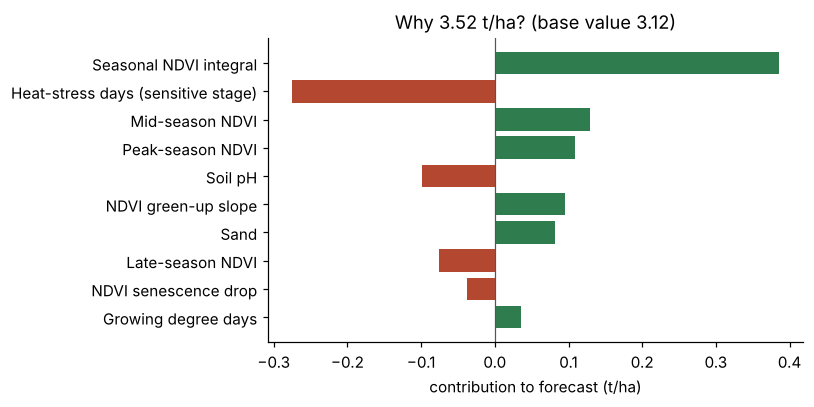

In [15]:
r = predictor.predict("Wheat", heatwave, district="Karnal")
items = [c for c in r["contributions"] if c["modality"] != "Context"][:10][::-1]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh([c["label"] for c in items], [c["contribution"] for c in items],
        color=[GREEN if c["contribution"] > 0 else "#b4472f" for c in items])
ax.axvline(0, color="#555", lw=0.8)
ax.set_xlabel("contribution to forecast (t/ha)")
ax.set_title(f"Why {r['predicted_yield_t_ha']:.2f} t/ha? (base value {r['base_value']:.2f})"); plt.tight_layout()

## Conclusion
* Fusing satellite, weather and soil raises LOYO R² from 0.70 (best single source) to 0.82.
* Early-fusion LightGBM forecasts unseen seasons with about 0.37 t/ha RMSE (about 10% error).
* SHAP shows how much satellite, weather and soil pushed each forecast.

**Data note:** NDVI, soil and yield are simulated with agronomic response curves; weather can be switched to real NASA POWER
data (`python -m cropyield.nasa_power`, then rebuild and retrain). See `docs/PROJECT_REPORT.md`.